In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt


In [2]:
df= pd.read_csv('Skyrun dataset.csv',  parse_dates=['InvoiceDate'])
df[df['InvoiceNo'].astype(str).str.startswith('C')].head()
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')].copy()
print('Rows left:', len(df))
df['Revenue'] = df['Quantity'] * df['UnitPrice']
df.describe

Rows left: 532621


<bound method NDFrame.describe of        InvoiceNo         InvoiceDate  CustomerID StockCode  Description  \
0         536365 2024-12-01 08:26:00     17850.0    SC1734  Electronics   
1         536365 2024-12-01 08:26:00     17850.0    SC2088    Furniture   
2         536365 2024-12-01 08:26:00     17850.0    SC3463        Books   
3         536365 2024-12-01 08:26:00     17850.0    SC6228         Toys   
4         536365 2024-12-01 08:26:00     17850.0    SC2149         Toys   
...          ...                 ...         ...       ...          ...   
541904    581587 2025-12-09 12:50:00     12680.0    SC5440    Furniture   
541905    581587 2025-12-09 12:50:00     12680.0    SC3576       Cloths   
541906    581587 2025-12-09 12:50:00     12680.0    SC5283    Furniture   
541907    581587 2025-12-09 12:50:00     12680.0    SC1099    Cosmetics   
541908    581587 2025-12-09 12:50:00     12680.0    SC9276         Toys   

        Quantity  UnitPrice       Country  Revenue  
0           

In [3]:
df = df.dropna(subset=['CustomerID']).copy()

In [4]:
num_customer = df['CustomerID'].nunique()      # 4,372
num_transaction = df['InvoiceNo'].nunique()    # 22,190 (one invoice = one order)
num_products = df['StockCode'].nunique()       # 9,000

In [5]:
df['InvoiceMonth'] = df['InvoiceDate'].dt.to_period('M')
df['Revenue'] = df['Quantity'] * df['UnitPrice']   

In [6]:
cohort_data = df.groupby('CustomerID')['InvoiceMonth'].min()

In [7]:
cohort_data.name = 'CohortMonth'
df = df.merge(cohort_data, on='CustomerID')

In [8]:
df.describe

<bound method NDFrame.describe of        InvoiceNo         InvoiceDate  CustomerID StockCode  Description  \
0         536365 2024-12-01 08:26:00     17850.0    SC1734  Electronics   
1         536365 2024-12-01 08:26:00     17850.0    SC2088    Furniture   
2         536365 2024-12-01 08:26:00     17850.0    SC3463        Books   
3         536365 2024-12-01 08:26:00     17850.0    SC6228         Toys   
4         536365 2024-12-01 08:26:00     17850.0    SC2149         Toys   
...          ...                 ...         ...       ...          ...   
397919    581587 2025-12-09 12:50:00     12680.0    SC5440    Furniture   
397920    581587 2025-12-09 12:50:00     12680.0    SC3576       Cloths   
397921    581587 2025-12-09 12:50:00     12680.0    SC5283    Furniture   
397922    581587 2025-12-09 12:50:00     12680.0    SC1099    Cosmetics   
397923    581587 2025-12-09 12:50:00     12680.0    SC9276         Toys   

        Quantity  UnitPrice       Country  Revenue InvoiceMonth C

In [9]:
invoice_year, invoice_month = df['InvoiceMonth'].dt.year, df['InvoiceMonth'].dt.month
cohort_year, cohort_month = df['CohortMonth'].dt.year, df['CohortMonth'].dt.month
df['CohortIndex'] = (invoice_year - cohort_year) * 12 + (invoice_month - cohort_month) + 1

In [10]:
# CORRECTION 1: leave out December 2025 (only 9 days of data)
complete = df[df['InvoiceMonth'].astype(str) != '2025-12']

cohort_counts = complete.groupby(['CohortMonth', 'CohortIndex'])['CustomerID'].nunique().reset_index()

In [11]:
cohort_pivot = cohort_counts.pivot(index='CohortMonth', columns='CohortIndex', values='CustomerID')

# CORRECTION 2: remove the December 2024 row (mostly existing customers, not new ones)
cohort_pivot = cohort_pivot[cohort_pivot.index.astype(str) != '2024-12']
cohort_pivot = cohort_pivot.dropna(axis=1, how='all')   # drop columns that are now empty

In [12]:
cohort_size = cohort_pivot.iloc[:, 0]
retention = cohort_pivot.divide(cohort_size, axis=0)

print('Average month-2 retention:', round(retention[2].mean() * 100), '%')
print('Range:', round(retention[2].min() * 100), '% to', round(retention[2].max() * 100), '%')

Average month-2 retention: 20 %
Range: 15 % to 24 %


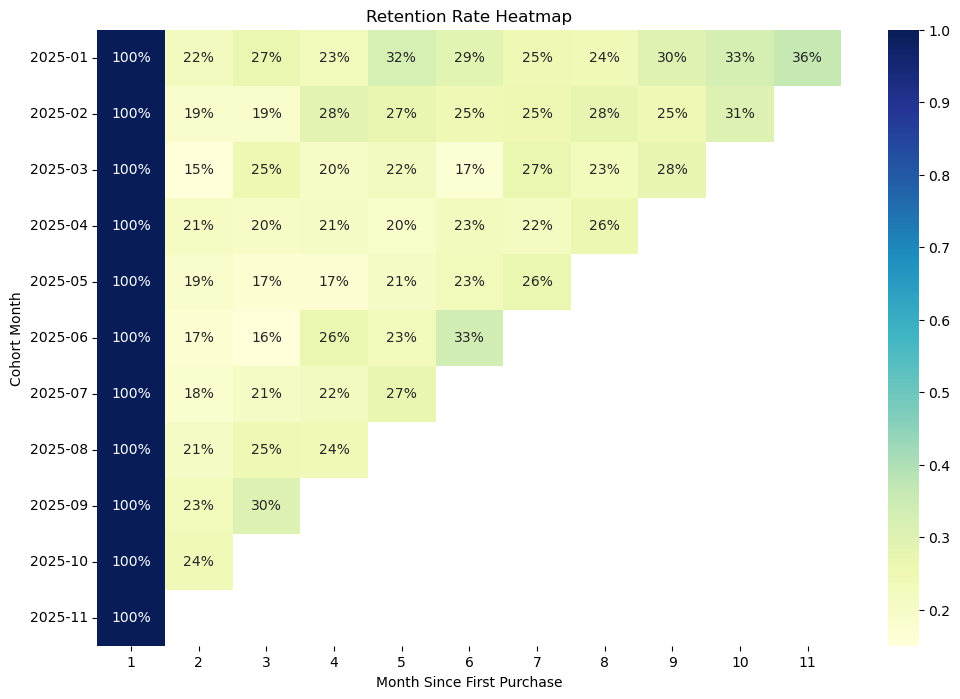

In [13]:
plt.figure(figsize=(12, 8))
sns.heatmap(retention, annot=True, fmt='.0%', cmap='YlGnBu')
plt.title('Retention Rate Heatmap')
plt.xlabel('Month Since First Purchase')
plt.ylabel('Cohort Month')
plt.savefig('Retention_heatmap.png')
plt.show()

In [14]:
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

In [15]:
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'InvoiceNo': pd.Series.nunique,
    'Revenue': 'sum'
}).reset_index()

In [16]:
rfm.columns = ['CustomerID', 'recency_days', 'frequency', 'monetary']

In [17]:
X = rfm[['recency_days', 'frequency', 'monetary']].copy()

In [18]:
X['frequency'] = np.log1p(X['frequency'])
X['monetary'] = np.log1p(X['monetary'])

In [19]:
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()
X_scaled = ss.fit_transform(X)

In [20]:
%pip install yellowbrick

Note: you may need to restart the kernel to use updated packages.


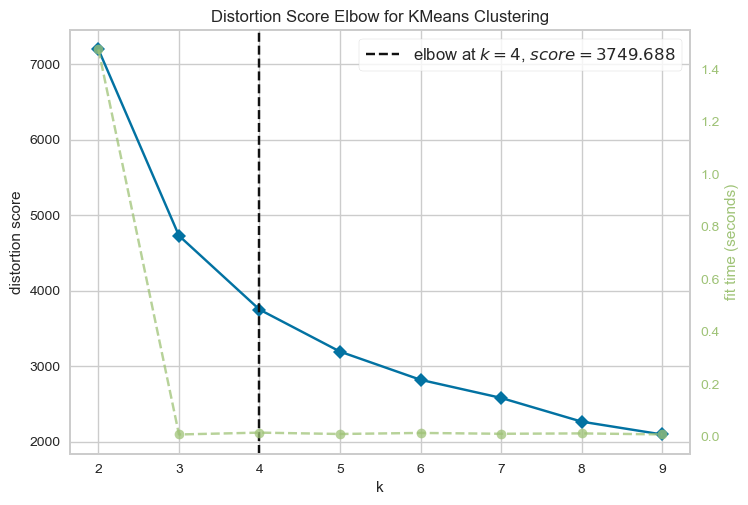

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [21]:
from sklearn.cluster import KMeans
from yellowbrick.cluster import KElbowVisualizer 

model = KMeans(random_state=30)
v = KElbowVisualizer(model, k=(2, 10))
v.fit(X_scaled)
v.show()

In [22]:
final_model = KMeans(n_clusters=4, random_state=42)
final_model.fit(X_scaled)

,n_clusters,4
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [23]:
rfm['Cluster'] = final_model.labels_

In [24]:
cluster_profile = rfm.groupby('Cluster').agg({
    'recency_days': 'mean',
    'frequency': 'mean',
    'monetary': 'mean',
    'CustomerID': 'count'
}).rename(columns={'CustomerID': 'NumCustomers'}).round(1)

In [25]:
cluster_profile

,recency_days,frequency,monetary,NumCustomers
Cluster,,,,
0,62.0,1.5,49688.1,1187
1,262.1,1.4,58116.1,917
2,18.8,14.6,829944.9,669
3,47.8,3.7,221666.5,1566


In [28]:
cluster_names = {0: 'New One-Time Buyers', 1: 'Lost One-Time Buyers', 2: 'Champions', 3: 'Loyal Repeaters'}
cluster_profile['Segment'] = cluster_profile.index.map(cluster_names)
cluster_profile

,recency_days,frequency,monetary,NumCustomers,Segment
Cluster,,,,,
0,62.0,1.5,49688.1,1187,New One-Time Buyers
1,262.1,1.4,58116.1,917,Lost One-Time Buyers
2,18.8,14.6,829944.9,669,Champions
3,47.8,3.7,221666.5,1566,Loyal Repeaters


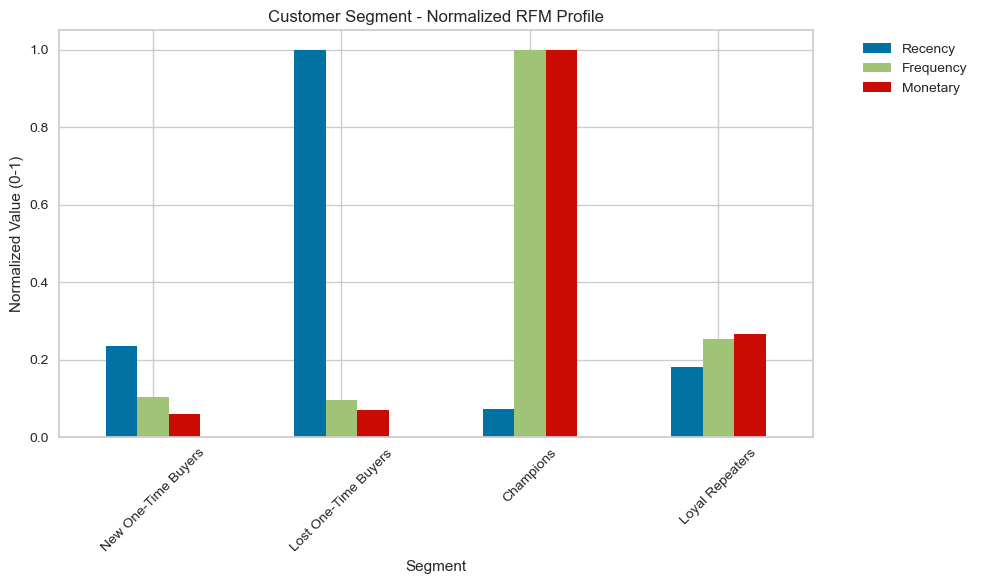

In [29]:
df_plot = cluster_profile.copy()
cols = ['recency_days', 'frequency', 'monetary']
df_plot[cols] = df_plot[cols].apply(lambda x: x / x.max())

df_plot.set_index('Segment')[cols].plot(kind='bar', figsize=(10, 6))
plt.title('Customer Segment - Normalized RFM Profile')
plt.ylabel('Normalized Value (0-1)')
plt.xticks(rotation=45)
plt.legend(['Recency', 'Frequency', 'Monetary'], bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('rfm_profile.png')
plt.show()